In [1]:
from pathlib import Path

project_dir = Path.cwd().parent

for path in project_dir.rglob("*.py"):
    if any(part.startswith(".") for part in path.parts):
        continue

    try:
        source = path.read_text(encoding="utf-8", errors="ignore")
    except Exception:
        continue

    if any(term in source.lower() for term in [
        "transformerdecoder",
        "multiheadattention",
        "vit",
        "visiontransformer"
    ]):
        print(f"\n--- {path.relative_to(project_dir)} ---")

        for line_no, line in enumerate(source.splitlines(), start=1):
            if any(term in line.lower() for term in [
                "class ",
                "transformerdecoder",
                "multiheadattention",
                "attention",
                "forward(",
                "vit"
            ]):
                print(f"{line_no}: {line.strip()}")

In [2]:
import json
from pathlib import Path

notebook_dir = Path.cwd()
found = False

for path in notebook_dir.rglob("*.ipynb"):
    if "phase4_outputs" in str(path):
        continue

    try:
        nb = json.loads(path.read_text(encoding="utf-8"))
    except Exception:
        continue

    matches = []

    for i, cell in enumerate(nb.get("cells", [])):
        if cell.get("cell_type") != "code":
            continue

        source = "".join(cell.get("source", []))

        if any(term in source.lower() for term in [
            "transformerdecoder",
            "multiheadattention",
            "class vit",
            "class transformer",
            "class caption"
        ]):
            matches.append((i + 1, source[:500]))

    if matches:
        found = True
        print(f"\nNotebook: {path.name}")
        for cell_no, source in matches:
            print(f"\nCell {cell_no}:\n{source}\n")

if not found:
    print("No matching model definitions found in notebook files.")


Notebook: 01_dataset_exploration.ipynb

Cell 48:
class CaptionDecoder(nn.Module):

    def __init__(self, vocab_size, embed_size=256, hidden_size=512):
        super().__init__()

        self.embedding = nn.Embedding(vocab_size, embed_size)

        self.lstm = nn.LSTM(
            embed_size,
            hidden_size,
            batch_first=True
        )

        self.fc = nn.Linear(hidden_size, vocab_size)

    def forward(self, captions):
        embeddings = self.embedding(captions)

        lstm_output, _ = self.lstm(embeddings)

      


Notebook: baseline_cnn_lstm.ipynb

Cell 9:
class CaptionDecoder(nn.Module):
    def __init__(
        self,
        vocab_size,
        embed_size=256,
        hidden_size=512,
        feature_size=2048
    ):
        super().__init__()

        # Convert ResNet features into LSTM hidden-state size
        self.feature_projection = nn.Linear(
            feature_size,
            hidden_size
        )

        # Convert word IDs into dense wor

In [3]:
import json
import torch
import torch.nn as nn
import math
from pathlib import Path

# Paths
NOTEBOOK_DIR = Path.cwd()
PROJECT_DIR = NOTEBOOK_DIR.parent
CHECKPOINT_PATH = (
    NOTEBOOK_DIR
    / "checkpoints_vit_transformer"
    / "best_vit_transformer.pth"
)

# Load vocabulary
with open(NOTEBOOK_DIR / "vocabulary.json", "r", encoding="utf-8") as f:
    vocab_data = json.load(f)

id_to_word = {int(idx): word for word, idx in vocab_data.items()}

VOCAB_SIZE = len(vocab_data)
device = torch.device("cpu")

print("Vocabulary size:", VOCAB_SIZE)
print("Checkpoint exists:", CHECKPOINT_PATH.exists())

Vocabulary size: 12076
Checkpoint exists: True


In [4]:
class TransformerCaptionDecoder(nn.Module):
    def __init__(
        self,
        vocab_size,
        visual_dim=768,
        embed_dim=256,
        num_heads=8,
        num_layers=3,
        feedforward_dim=1024,
        max_length=38,
        dropout=0.1
    ):
        super().__init__()

        self.embed_dim = embed_dim
        self.max_length = max_length

        self.embedding = nn.Embedding(
            vocab_size, embed_dim, padding_idx=0
        )
        self.visual_projection = nn.Linear(
            visual_dim, embed_dim
        )
        self.position_embedding = nn.Embedding(
            max_length, embed_dim
        )

        decoder_layer = nn.TransformerDecoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=feedforward_dim,
            dropout=dropout,
            batch_first=True
        )
        self.transformer_decoder = nn.TransformerDecoder(
            decoder_layer, num_layers=num_layers
        )
        self.output_layer = nn.Linear(embed_dim, vocab_size)

    def forward(self, visual_features, caption_ids):
        batch_size, caption_length = caption_ids.shape
        memory = self.visual_projection(visual_features)

        positions = torch.arange(
            caption_length, device=caption_ids.device
        ).unsqueeze(0).expand(batch_size, -1)

        target = (
            self.embedding(caption_ids) * math.sqrt(self.embed_dim)
            + self.position_embedding(positions)
        )

        causal_mask = torch.triu(
            torch.ones(
                caption_length, caption_length,
                device=caption_ids.device, dtype=torch.bool
            ),
            diagonal=1
        )

        padding_mask = caption_ids.eq(0)

        decoded = self.transformer_decoder(
            tgt=target,
            memory=memory,
            tgt_mask=causal_mask,
            tgt_key_padding_mask=padding_mask
        )

        return self.output_layer(decoded)


transformer_decoder = TransformerCaptionDecoder(
    vocab_size=VOCAB_SIZE
).to(device)

checkpoint = torch.load(
    CHECKPOINT_PATH,
    map_location=device,
    weights_only=True
)

transformer_decoder.load_state_dict(checkpoint["model_state_dict"])
transformer_decoder.eval()

print("Trained Transformer loaded successfully.")
print("Checkpoint epoch:", checkpoint["epoch"])
print("Validation loss:", round(checkpoint["val_loss"], 4))
print("Evaluation mode:", not transformer_decoder.training)

Trained Transformer loaded successfully.
Checkpoint epoch: 4
Validation loss: 3.2314
Evaluation mode: True


In [5]:
FEATURES_PATH = NOTEBOOK_DIR / "cached_features" / "test_features.pt"

print("Feature file exists:", FEATURES_PATH.exists())

test_features = torch.load(
    FEATURES_PATH,
    map_location=device,
    weights_only=True
)

print("Number of test images:", len(test_features))

sample_name = next(iter(test_features))
print("Sample image:", sample_name)
print("Feature shape:", test_features[sample_name].shape)

Feature file exists: True
Number of test images: 2
Sample image: features
Feature shape: torch.Size([5000, 2048])


In [6]:
from pathlib import Path
import torch

print("Searching for cached feature files...\n")

for path in PROJECT_DIR.rglob("*.pt"):
    if "feature" in path.name.lower():
        try:
            data = torch.load(
                path, map_location="cpu", weights_only=True
            )
            print(f"\nFile: {path}")
            print("Type:", type(data).__name__)

            if isinstance(data, dict):
                for key, value in list(data.items())[:5]:
                    if torch.is_tensor(value):
                        print(f"  {key}: {tuple(value.shape)}")
                    else:
                        print(f"  {key}: {type(value).__name__}")
            elif torch.is_tensor(data):
                print("Shape:", tuple(data.shape))

        except Exception as e:
            print(f"Could not inspect {path.name}: {e}")

Searching for cached feature files...


File: C:\Users\rajva\Desktop\image-captioning Project\notebook\cached_features\test_features.pt
Type: dict
  features: (5000, 2048)
  captions: (5000, 38)

File: C:\Users\rajva\Desktop\image-captioning Project\notebook\cached_features\train_features.pt
Type: dict
  features: (30000, 2048)
  captions: (30000, 38)

File: C:\Users\rajva\Desktop\image-captioning Project\notebook\cached_features\val_features.pt
Type: dict
  features: (5000, 2048)
  captions: (5000, 38)

File: C:\Users\rajva\Desktop\image-captioning Project\notebook\vit_cached_features\test_vit_features.pt
Type: dict
  1056338697_4f7d7ce270.jpg: (196, 768)
  106490881_5a2dd9b7bd.jpg: (196, 768)
  1082379191_ec1e53f996.jpg: (196, 768)
  1084040636_97d9633581.jpg: (196, 768)
  1096395242_fc69f0ae5a.jpg: (196, 768)

File: C:\Users\rajva\Desktop\image-captioning Project\notebook\vit_cached_features\train_vit_features.pt
Type: dict
  1000268201_693b08cb0e.jpg: (196, 768)
  1001773457_577c3a

## Load ViT test features

In [7]:
FEATURES_PATH = NOTEBOOK_DIR / "vit_cached_features" / "test_vit_features.pt"

test_features = torch.load(
    FEATURES_PATH,
    map_location=device,
    weights_only=True
)

print("Number of test images:", len(test_features))

sample_name = next(iter(test_features))
print("Sample image:", sample_name)
print("Feature shape:", test_features[sample_name].shape)

assert test_features[sample_name].shape == (196, 768)
print("Correct ViT features loaded successfully!")

Number of test images: 1000
Sample image: 1056338697_4f7d7ce270.jpg
Feature shape: torch.Size([196, 768])
Correct ViT features loaded successfully!


In [8]:
import torch.nn as nn

for name, obj in list(globals().items()):
    if isinstance(obj, nn.Module):
        print(f"{name}: {type(obj).__name__}")

transformer_decoder: TransformerCaptionDecoder


In [9]:
import inspect

print("Decoder class:", type(transformer_decoder).__name__)

print("\nForward method signature:")
print(inspect.signature(transformer_decoder.forward))

print("\nDecoder components:")
for name, module in transformer_decoder.named_children():
    print(f"{name}: {type(module).__name__}")

print("\nEvaluation mode:", not transformer_decoder.training)

Decoder class: TransformerCaptionDecoder

Forward method signature:
(visual_features, caption_ids)

Decoder components:
embedding: Embedding
visual_projection: Linear
position_embedding: Embedding
transformer_decoder: TransformerDecoder
output_layer: Linear

Evaluation mode: True


In [10]:
import inspect

print(inspect.getsource(TransformerCaptionDecoder.forward))

    def forward(self, visual_features, caption_ids):
        batch_size, caption_length = caption_ids.shape
        memory = self.visual_projection(visual_features)

        positions = torch.arange(
            caption_length, device=caption_ids.device
        ).unsqueeze(0).expand(batch_size, -1)

        target = (
            self.embedding(caption_ids) * math.sqrt(self.embed_dim)
            + self.position_embedding(positions)
        )

        causal_mask = torch.triu(
            torch.ones(
                caption_length, caption_length,
                device=caption_ids.device, dtype=torch.bool
            ),
            diagonal=1
        )

        padding_mask = caption_ids.eq(0)

        decoded = self.transformer_decoder(
            tgt=target,
            memory=memory,
            tgt_mask=causal_mask,
            tgt_key_padding_mask=padding_mask
        )

        return self.output_layer(decoded)



## Check vocabulary and generation settings

In [11]:
print("Decoder settings:")
for attr in ["embed_dim", "vocab_size", "max_seq_length", "max_len"]:
    if hasattr(transformer_decoder, attr):
        print(f"{attr}: {getattr(transformer_decoder, attr)}")

print("\nPossible vocabulary variables:")
for name, obj in list(globals().items()):
    if isinstance(obj, dict) and len(obj) > 1000:
        print(f"{name}: {len(obj)} entries")
        print("  Sample:", list(obj.items())[:5])

Decoder settings:
embed_dim: 256

Possible vocabulary variables:
vocab_data: 12076 entries
  Sample: [('<PAD>', 0), ('<START>', 1), ('<END>', 2), ('<UNK>', 3), ('"', 4)]
id_to_word: 12076 entries
  Sample: [(0, '<PAD>'), (1, '<START>'), (2, '<END>'), (3, '<UNK>'), (4, '"')]


In [12]:
# Select a different test image
sample_name = list(test_features.keys())[2]

visual_features = test_features[sample_name].to(device).float().unsqueeze(0)
generated_ids = [vocab_data["<START>"]]
word_confidences = []

transformer_decoder.eval()

with torch.no_grad():
    for _ in range(37):
        caption_ids = torch.tensor([generated_ids], device=device)
        logits = transformer_decoder(visual_features, caption_ids)

        probabilities = torch.softmax(logits[0, -1, :], dim=-1)
        next_id = int(probabilities.argmax().item())
        confidence = float(probabilities[next_id].item())

        if next_id == vocab_data["<END>"]:
            break

        generated_ids.append(next_id)
        word_confidences.append(confidence)

generated_words = [id_to_word[token_id] for token_id in generated_ids[1:]]

print("Image:", sample_name)
print("Generated caption:", " ".join(generated_words))
print("\nWord-level confidence:")

for word, confidence in zip(generated_words, word_confidences):
    print(f"{word:20s} {confidence:.4f}")

if word_confidences:
    print("\nMean token confidence:",
          round(sum(word_confidences) / len(word_confidences), 4))

Image: 1082379191_ec1e53f996.jpg
Generated caption: a man sitting on a bench in the middle of a boat on a lake.

Word-level confidence:
a                    0.3923
man                  0.4420
sitting              0.2007
on                   0.6492
a                    0.8746
bench                0.1566
in                   0.1440
the                  0.5366
middle               0.1644
of                   0.9749
a                    0.7283
boat                 0.1843
on                   0.2152
a                    0.6758
lake.                0.1347

Mean token confidence: 0.4316


## Analyze all 1,000 test images

In [13]:
import json
import pandas as pd
from pathlib import Path
import torch

transformer_decoder.eval()

OUTPUT_DIR = NOTEBOOK_DIR / "phase5_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

START_ID = vocab_data["<START>"]
END_ID = vocab_data["<END>"]
PAD_ID = vocab_data["<PAD>"]

image_names = list(test_features.keys())
BATCH_SIZE = 16
MAX_NEW_TOKENS = 37

caption_results = []
token_results = []

for batch_start in range(0, len(image_names), BATCH_SIZE):
    batch_names = image_names[batch_start:batch_start + BATCH_SIZE]

    visual_batch = torch.stack([
        test_features[name].float() for name in batch_names
    ]).to(device)

    batch_size = len(batch_names)
    sequences = [[START_ID] for _ in batch_names]
    finished = [False] * batch_size
    words_per_image = [[] for _ in batch_names]
    confidences_per_image = [[] for _ in batch_names]

    with torch.no_grad():
        for _ in range(MAX_NEW_TOKENS):
            caption_ids = torch.tensor(sequences, dtype=torch.long, device=device)

            logits = transformer_decoder(visual_batch, caption_ids)
            next_logits = logits[:, -1, :]
            probabilities = torch.softmax(next_logits, dim=-1)

            next_ids = probabilities.argmax(dim=-1)
            next_confidences = probabilities.gather(
                1, next_ids.unsqueeze(1)
            ).squeeze(1)

            for i in range(batch_size):
                if finished[i]:
                    sequences[i].append(PAD_ID)
                    continue

                token_id = int(next_ids[i].item())
                confidence = float(next_confidences[i].item())

                if token_id == END_ID:
                    finished[i] = True
                    sequences[i].append(PAD_ID)
                    continue

                word = id_to_word.get(token_id, "<UNK>")
                words_per_image[i].append(word)
                confidences_per_image[i].append(confidence)
                sequences[i].append(token_id)

            if all(finished):
                break

    for i, image_name in enumerate(batch_names):
        words = words_per_image[i]
        confidences = confidences_per_image[i]
        caption = " ".join(words)

        caption_results.append({
            "image": image_name,
            "caption": caption,
            "token_count": len(words),
            "mean_confidence": (
                sum(confidences) / len(confidences) if confidences else 0.0
            ),
            "min_confidence": min(confidences) if confidences else 0.0,
            "max_confidence": max(confidences) if confidences else 0.0,
            "token_confidences": json.dumps(confidences)
        })

        for position, (word, confidence) in enumerate(
            zip(words, confidences), start=1
        ):
            token_results.append({
                "image": image_name,
                "position": position,
                "word": word,
                "confidence": confidence
            })

    completed = min(batch_start + batch_size, len(image_names))
    if completed % 100 == 0 or completed == len(image_names):
        print(f"Processed {completed}/{len(image_names)} images")

caption_df = pd.DataFrame(caption_results)
token_df = pd.DataFrame(token_results)

caption_df.to_csv(OUTPUT_DIR / "word_confidence_captions.csv", index=False)
token_df.to_csv(OUTPUT_DIR / "word_confidence_tokens.csv", index=False)

print("\nSaved results to:", OUTPUT_DIR)
print("Caption records:", len(caption_df))
print("Token records:", len(token_df))
print("\nMean image-level confidence:",
      round(caption_df["mean_confidence"].mean(), 4))
print("\nLowest-confidence captions:")
print(caption_df.nsmallest(5, "mean_confidence")[
    ["image", "caption", "mean_confidence"]
].to_string(index=False))


Processed 400/1000 images
Processed 800/1000 images
Processed 1000/1000 images

Saved results to: C:\Users\rajva\Desktop\image-captioning Project\notebook\phase5_outputs
Caption records: 1000
Token records: 13647

Mean image-level confidence: 0.4129

Lowest-confidence captions:
                    image                                                                                                                                                                             caption  mean_confidence
 398662202_97e5819b79.jpg                                                                                                                 two children playing with a toy and a game of playground equipment.         0.196407
2666205903_8d287669e1.jpg                                                  a boy is playing with a colorful colored plastic toy and a blue and blue and blue shirt is holding a colorful colored plastic bag.         0.197965
 491405109_798222cfd0.jpg                     two gi

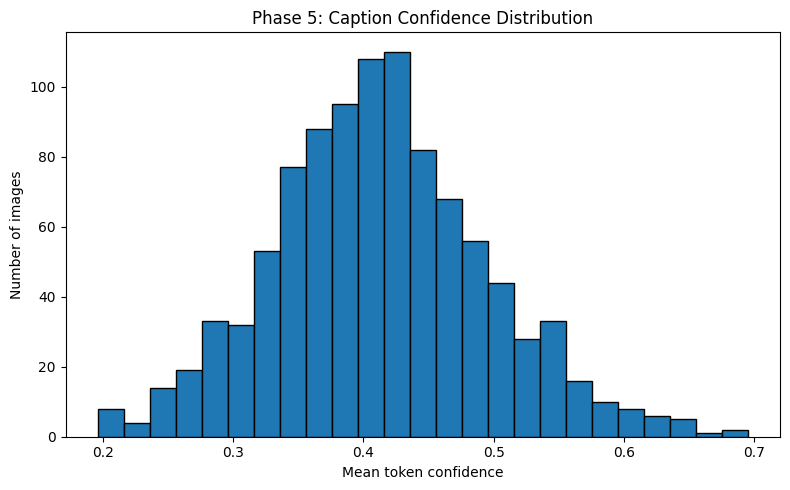

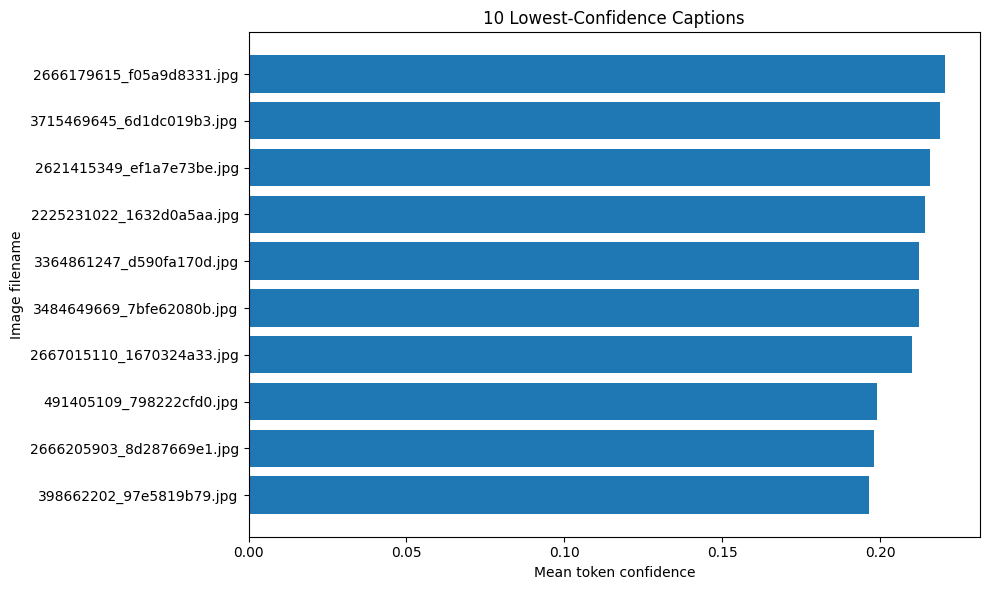

Captions with the most repeated bigrams:
                    image                                                                                                                                                                    caption  mean_confidence  repeated_bigram_ratio
2124040721_bffc0a091a.jpg                   a person wearing a red hat is wearing a red hat and red hat and red hat and red hat is wearing a red hat and red hat and red hat and red hat and red hat         0.363418               0.750000
 754852108_72f80d421f.jpg                               a man wearing a hat and hat is wearing a hat and hat and a hat and a hat is wearing a hat and hat and a hat and a hat and a hat is wearing a         0.328834               0.750000
1237985362_dbafc59280.jpg        a boy in a blue shirt is holding a blue and blue and blue and blue and blue shirt and blue and blue and blue shirt is holding a blue and blue and blue and blue and         0.287236               0.694444
 522063319_

In [14]:
import matplotlib.pyplot as plt
import pandas as pd
import re

# Use results already generated in Step 6
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Calculate simple repetition indicators
def repetition_stats(caption):
    words = re.findall(r"\b[\w'-]+\b", caption.lower())

    if not words:
        return pd.Series({
            "unique_word_ratio": 0.0,
            "repeated_bigram_ratio": 0.0
        })

    bigrams = list(zip(words, words[1:]))

    return pd.Series({
        "unique_word_ratio": len(set(words)) / len(words),
        "repeated_bigram_ratio": (
            1 - len(set(bigrams)) / len(bigrams)
            if bigrams else 0.0
        )
    })

repetition_df = caption_df["caption"].apply(repetition_stats)
error_df = pd.concat([caption_df, repetition_df], axis=1)

error_df.to_csv(
    OUTPUT_DIR / "phase5_error_analysis.csv",
    index=False
)

# 2. Plot confidence distribution
plt.figure(figsize=(8, 5))
plt.hist(caption_df["mean_confidence"], bins=25, edgecolor="black")
plt.xlabel("Mean token confidence")
plt.ylabel("Number of images")
plt.title("Phase 5: Caption Confidence Distribution")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confidence_distribution.png", dpi=150)
plt.show()

# 3. Plot the 10 lowest-confidence captions
lowest = caption_df.nsmallest(10, "mean_confidence").sort_values(
    "mean_confidence"
)

plt.figure(figsize=(10, 6))
plt.barh(
    lowest["image"],
    lowest["mean_confidence"]
)
plt.xlabel("Mean token confidence")
plt.ylabel("Image filename")
plt.title("10 Lowest-Confidence Captions")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "lowest_confidence_captions.png", dpi=150)
plt.show()

# 4. Show captions with the most repeated bigrams
print("Captions with the most repeated bigrams:")
print(
    error_df.nlargest(5, "repeated_bigram_ratio")[
        ["image", "caption", "mean_confidence", "repeated_bigram_ratio"]
    ].to_string(index=False)
)

print("\nMean unique-word ratio:",
      round(error_df["unique_word_ratio"].mean(), 4))
print("Saved error analysis:", OUTPUT_DIR / "phase5_error_analysis.csv")
print("Saved visualizations:", OUTPUT_DIR)

## Inspecting  the attention layers

In [15]:
decoder_layers = transformer_decoder.transformer_decoder.layers

print("Number of Transformer decoder layers:", len(decoder_layers))

for i, layer in enumerate(decoder_layers):
    print(f"\nLayer {i + 1}")
    print("Self-attention heads:",
          layer.self_attn.num_heads)
    print("Cross-attention heads:",
          layer.multihead_attn.num_heads)
    print("Cross-attention module:",
          type(layer.multihead_attn).__name__)

print("\nViT feature shape:", test_features[sample_name].shape)
print("Model is in evaluation mode:", not transformer_decoder.training)

Number of Transformer decoder layers: 3

Layer 1
Self-attention heads: 8
Cross-attention heads: 8
Cross-attention module: MultiheadAttention

Layer 2
Self-attention heads: 8
Cross-attention heads: 8
Cross-attention module: MultiheadAttention

Layer 3
Self-attention heads: 8
Cross-attention heads: 8
Cross-attention module: MultiheadAttention

ViT feature shape: torch.Size([196, 768])
Model is in evaluation mode: True


## Extract cross-attention weights


In [16]:
import types
import torch
import matplotlib.pyplot as plt
import numpy as np

transformer_decoder.eval()

# Select one test image
sample_name = next(iter(test_features))
visual_features = (
    test_features[sample_name]
    .float()
    .to(device)
    .unsqueeze(0)
)

decoder_layers = transformer_decoder.transformer_decoder.layers
captured_attention = {}
original_forwards = []

# Temporarily enable attention-weight output in each cross-attention layer
for layer_idx, layer in enumerate(decoder_layers):
    attention_module = layer.multihead_attn
    original_forward = attention_module.forward
    original_forwards.append((attention_module, original_forward))

    def make_wrapper(idx, original):
        def wrapped_forward(query, key, value, *args, **kwargs):
            kwargs["need_weights"] = True
            kwargs["average_attn_weights"] = False

            output, weights = original(
                query, key, value, *args, **kwargs
            )

            if weights is not None:
                captured_attention[idx] = weights.detach().cpu()

            return output, weights

        return wrapped_forward

    attention_module.forward = make_wrapper(
        layer_idx, original_forward
    )

generated_ids = [vocab_data["<START>"]]
generated_words = []
attention_maps = []

try:
    with torch.no_grad():
        for _ in range(37):
            caption_ids = torch.tensor(
                [generated_ids], dtype=torch.long, device=device
            )

            captured_attention.clear()
            logits = transformer_decoder(
                visual_features, caption_ids
            )

            next_id = int(logits[0, -1].argmax().item())

            if next_id == vocab_data["<END>"]:
                break

            generated_ids.append(next_id)
            generated_words.append(
                id_to_word.get(next_id, "<UNK>")
            )

            # Last decoder layer: average its 8 heads
            last_layer_weights = captured_attention[len(decoder_layers) - 1]

            # Expected shape: (batch, heads, target_length, 196)
            last_word_attention = (
                last_layer_weights[0, :, -1, :]
                .mean(dim=0)
                .numpy()
            )

            attention_maps.append(
                last_word_attention.reshape(14, 14)
            )

finally:
    # Restore the original methods
    for module, original_forward in original_forwards:
        module.forward = original_forward

print("Image:", sample_name)
print("Generated caption:", " ".join(generated_words))
print("Attention maps captured:", len(attention_maps))

assert len(attention_maps) == len(generated_words)
print("Cross-attention extraction completed successfully!")

Image: 1056338697_4f7d7ce270.jpg
Generated caption: a girl in a blue shirt is jumping into the air.
Attention maps captured: 11
Cross-attention extraction completed successfully!


## Visualize attention for each word

In [37]:
# List available test images
test_image_names = list(test_features.keys())

print("Total test images:", len(test_image_names))

for i, name in enumerate(test_image_names[:10]):
    print(f"{i}: {name}")

# Select a different image by changing the index
image_index = 4
sample_name = test_image_names[image_index]

print("\nSelected image:", sample_name)

Total test images: 1000
0: 1056338697_4f7d7ce270.jpg
1: 106490881_5a2dd9b7bd.jpg
2: 1082379191_ec1e53f996.jpg
3: 1084040636_97d9633581.jpg
4: 1096395242_fc69f0ae5a.jpg
5: 1107246521_d16a476380.jpg
6: 1119015538_e8e796281e.jpg
7: 1122944218_8eb3607403.jpg
8: 1131800850_89c7ffd477.jpg
9: 1131932671_c8d17751b3.jpg

Selected image: 1096395242_fc69f0ae5a.jpg


In [38]:
# Find existing variables that may contain dataset captions
for name, obj in globals().copy().items():
    try:
        if hasattr(obj, "columns"):
            print(f"\nDataFrame: {name}")
            print("Columns:", list(obj.columns))
        elif isinstance(obj, dict) and len(obj) > 0:
            first_value = next(iter(obj.values()))
            if isinstance(first_value, (str, list, tuple)):
                print(
                    f"\nDictionary: {name} | "
                    f"Entries: {len(obj)} | "
                    f"Example value: {str(first_value)[:100]}"
                )
    except Exception:
        pass


Dictionary: nb | Entries: 4 | Example value: [{'cell_type': 'code', 'execution_count': 4, 'id': 'f866c8f5-e0a6-492e-a389-040d3839d443', 'metadata

Dictionary: cell | Entries: 6 | Example value: code

Dictionary: id_to_word | Entries: 12076 | Example value: <PAD>

DataFrame: caption_df
Columns: ['image', 'caption', 'token_count', 'mean_confidence', 'min_confidence', 'max_confidence', 'token_confidences']

DataFrame: token_df
Columns: ['image', 'position', 'word', 'confidence']

DataFrame: repetition_df
Columns: ['unique_word_ratio', 'repeated_bigram_ratio']

DataFrame: error_df
Columns: ['image', 'caption', 'token_count', 'mean_confidence', 'min_confidence', 'max_confidence', 'token_confidences', 'unique_word_ratio', 'repeated_bigram_ratio']

DataFrame: lowest
Columns: ['image', 'caption', 'token_count', 'mean_confidence', 'min_confidence', 'max_confidence', 'token_confidences']

DataFrame: reference_df
Columns: ['image_caption_id', 'caption', 'image']

DataFrame: image_refs
Columns: [

In [39]:
import pandas as pd

CAPTIONS_PATH = NOTEBOOK_DIR.parent / "data" / "raw" / "captions.txt"

# Load the tab-separated caption file
reference_df = pd.read_csv(
    CAPTIONS_PATH,
    sep="\t",
    header=None,
    names=["image_caption_id", "caption"],
    encoding="utf-8-sig"
)

# Remove caption index, e.g. #0, from each filename
reference_df["image"] = (
    reference_df["image_caption_id"]
    .str.rsplit("#", n=1)
    .str[0]
)

# Display references for the selected image
image_refs = reference_df[reference_df["image"] == sample_name]

print("Image:", sample_name)
print("\nOriginal reference captions:")

if image_refs.empty:
    print("No reference captions found for this filename.")
else:
    for i, caption in enumerate(image_refs["caption"], start=1):
        print(f"{i}. {caption.strip()}")

print("\nModel-generated caption:")
print(" ".join(generated_words))

Image: 1096395242_fc69f0ae5a.jpg

Original reference captions:
1. A boy with a toy gun .
2. A little boy in orange shorts playing with a toy .
3. A young boy with his foot outstretched aims a toy at the camera in front of a fireplace .
4. A young child plays with his new light-up toy .
5. Boy with toy gun pointed at the camera .

Model-generated caption:
a boy in a red shirt is playing with a toy on a chair in the floor.


In [40]:
import pandas as pd
from pathlib import Path

OUTPUT_DIR = NOTEBOOK_DIR / "phase5_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Collect the five reference captions
reference_captions = image_refs["caption"].astype(str).tolist()

# Create a record of this example
verified_case = pd.DataFrame([{
    "image": sample_name,
    "generated_caption": " ".join(generated_words),
    "reference_captions": " | ".join(
        caption.strip() for caption in reference_captions
    ),
    "observed_issue": (
        "Object/person/action mismatch: generated caption describes "
        "a girl jumping, while reference captions describe a boy "
        "playing with a toy."
    ),
    "case_status": "Manually verified caption mismatch"
}])

# Append if the file already exists; otherwise create it
case_path = OUTPUT_DIR / "verified_visual_error_cases.csv"

if case_path.exists():
    existing_cases = pd.read_csv(case_path)
    existing_cases = existing_cases[
        existing_cases["image"] != sample_name
    ]
    verified_case = pd.concat(
        [existing_cases, verified_case],
        ignore_index=True
    )

verified_case.to_csv(case_path, index=False)

print("Verified case saved:", case_path)
print("Image:", sample_name)
print("Generated:", " ".join(generated_words))
print("Reference captions:", len(reference_captions))

Verified case saved: C:\Users\rajva\Desktop\image-captioning Project\notebook\phase5_outputs\verified_visual_error_cases.csv
Image: 1096395242_fc69f0ae5a.jpg
Generated: a boy in a red shirt is playing with a toy on a chair in the floor.
Reference captions: 5


## Checking  the attention heatmaps

Selected image: 1167669558_87a8a467d6.jpg
Feature shape: (196, 768)


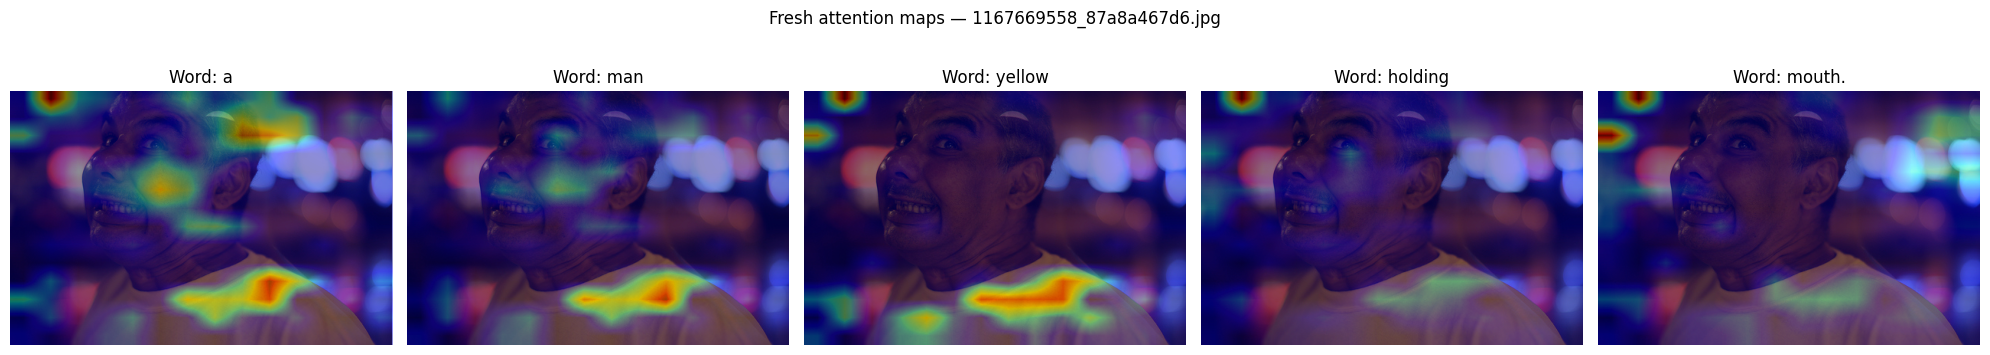

Image: 1167669558_87a8a467d6.jpg
Freshly generated caption: a man in a yellow shirt is holding a cigarette in his mouth.
Attention maps: 13


In [46]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Select the image explicitly
# sample_name = "1096395242_fc69f0ae5a.jpg"

# assert sample_name in test_features, (
#     f"{sample_name} is not present in test_features."
# )
# Select a different test image by index
test_image_names = list(test_features.keys())

image_index = 13  # Try 10, 20, 50, 100, etc.
assert 0 <= image_index < len(test_image_names), (
    f"Index must be between 0 and {len(test_image_names) - 1}."
)

sample_name = test_image_names[image_index]

# Validate the cached visual features
visual_tensor = test_features[sample_name]

assert isinstance(visual_tensor, torch.Tensor), (
    "Cached features are not a PyTorch tensor."
)
assert tuple(visual_tensor.shape) == (196, 768), (
    f"Unexpected feature shape: {tuple(visual_tensor.shape)}"
)

print("Selected image:", sample_name)
print("Feature shape:", tuple(visual_tensor.shape))
transformer_decoder.eval()

visual_features = (
    test_features[sample_name]
    .float()
    .to(device)
    .unsqueeze(0)
)

# Capture cross-attention from each decoder layer
captured_attention = {}
original_forwards = []

for layer_idx, layer in enumerate(
    transformer_decoder.transformer_decoder.layers
):
    attention_module = layer.multihead_attn
    original_forward = attention_module.forward
    original_forwards.append((attention_module, original_forward))

    def make_wrapper(idx, original):
        def wrapped_forward(query, key, value, *args, **kwargs):
            kwargs["need_weights"] = True
            kwargs["average_attn_weights"] = False
            output, weights = original(
                query, key, value, *args, **kwargs
            )
            if weights is not None:
                captured_attention[idx] = weights.detach().cpu()
            return output, weights
        return wrapped_forward

    attention_module.forward = make_wrapper(
        layer_idx, original_forward
    )

generated_ids = [vocab_data["<START>"]]
generated_words = []
attention_maps = []

try:
    with torch.no_grad():
        for _ in range(37):
            caption_ids = torch.tensor(
                [generated_ids], dtype=torch.long, device=device
            )

            captured_attention.clear()
            logits = transformer_decoder(
                visual_features, caption_ids
            )

            next_id = int(logits[0, -1].argmax().item())

            if next_id == vocab_data["<END>"]:
                break

            generated_ids.append(next_id)
            generated_words.append(
                id_to_word.get(next_id, "<UNK>")
            )

            last_layer_weights = captured_attention[
                len(transformer_decoder.transformer_decoder.layers) - 1
            ]

            word_attention = (
                last_layer_weights[0, :, -1, :]
                .mean(dim=0)
                .numpy()
            )

            attention_maps.append(
                word_attention.reshape(14, 14)
            )

finally:
    for module, original in original_forwards:
        module.forward = original

# Load the matching original image
IMAGE_DIR = NOTEBOOK_DIR.parent / "data" / "raw" / "Images"
image_path = IMAGE_DIR / sample_name

if not image_path.exists():
    matches = list(IMAGE_DIR.rglob(sample_name))
    if not matches:
        raise FileNotFoundError(f"Image not found: {sample_name}")
    image_path = matches[0]

image = Image.open(image_path).convert("RGB")

assert len(generated_words) == len(attention_maps) > 0

# Plot fresh attention maps
selected_indices = sorted(set([
    0, 1, 4, 7, len(generated_words) - 1
]))
selected_indices = [
    i for i in selected_indices if i < len(generated_words)
]

fig, axes = plt.subplots(
    1, len(selected_indices),
    figsize=(4 * len(selected_indices), 4),
    squeeze=False
)

for ax, idx in zip(axes[0], selected_indices):
    ax.imshow(image)
    ax.imshow(
        attention_maps[idx],
        cmap="jet",
        alpha=0.45,
        extent=(0, image.width, image.height, 0),
        interpolation="bilinear"
    )
    ax.set_title(f"Word: {generated_words[idx]}")
    ax.axis("off")

plt.suptitle(f"Fresh attention maps — {sample_name}")
plt.tight_layout()
plt.show()
plt.close(fig)

print("Image:", sample_name)
print("Freshly generated caption:", " ".join(generated_words))
print("Attention maps:", len(attention_maps))

In [42]:
attention_path = OUTPUT_DIR / "attention_boy_toy_fresh.png"

fig.savefig(attention_path, dpi=150, bbox_inches="tight")

print("Fresh attention visualization saved to:")
print(attention_path)

Fresh attention visualization saved to:
C:\Users\rajva\Desktop\image-captioning Project\notebook\phase5_outputs\attention_boy_toy_fresh.png


In [43]:
from pathlib import Path

OUTPUT_DIR = NOTEBOOK_DIR / "phase5_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

summary = """
PHASE 5: CONFIDENCE, ERROR ANALYSIS AND VISUAL EXPLAINABILITY
============================================================

Completed analyses:
1. Word-level confidence analysis on 1,000 test images.
2. Token-level confidence records: 13,647.
3. Repetition and low-confidence caption analysis.
4. ViT cross-attention visualization.
5. Manual verification of a caption mismatch against five reference captions.

Key results:
- Mean image-level confidence: 0.4129.
- Mean unique-word ratio: 0.8085.
- Example image: 1096395242_fc69f0ae5a.jpg
- Fresh generated caption: a boy in a red shirt is playing with a toy on a chair in the floor.
- Reference captions describe a boy playing with a toy.
- The example has possible unsupported details that warrant further review.

Important limitations:
- Confidence is not a measure of factual correctness.
- Attention maps are exploratory and do not prove why a caption was generated.
- A single example does not establish the overall hallucination rate.

Output files:
- word_confidence_captions.csv
- word_confidence_tokens.csv
- phase5_error_analysis.csv
- confidence_distribution.png
- lowest_confidence_captions.png
- verified_visual_error_cases.csv
- attention_boy_toy_fresh.png
"""

summary_path = OUTPUT_DIR / "phase5_summary.txt"
summary_path.write_text(summary.strip(), encoding="utf-8")

print("Phase 5 summary saved:", summary_path)

Phase 5 summary saved: C:\Users\rajva\Desktop\image-captioning Project\notebook\phase5_outputs\phase5_summary.txt
